In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
    ElasticNet
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [34]:
df = pd.read_csv("road_network.csv")
df.head()

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
0,RD-0001,Jl. Segment 1,Jalan Kolektor,4.3,4,60,5384,0,0,Cukup,21-12-2022,-6.173938,106.920654,-6.187271,106.937674,PIK,0,10833
1,RD-0002,Jl. Segment 2,Jalan Arteri,4.3,4,80,6132,0,0,Baik,17-11-2022,-6.248396,106.768647,-6.246220,106.771962,Depok,0,6921
2,RD-0003,Jl. Segment 3,Jalan Lokal,1.8,2,40,978,0,0,Cukup,15-04-2023,-6.267631,106.814963,-6.264098,106.831007,Tangerang,0,1085
3,RD-0004,Jl. Segment 4,Jalan Kolektor,1.8,4,60,4160,0,1,Rusak Berat,17-05-2022,-6.112216,106.954036,-6.122268,106.958261,Mangga Dua,0,6145
4,RD-0005,Jl. Segment 5,Jalan Tol,22.7,4,80,6600,1,0,Baik,16-02-2024,-6.349760,106.861835,-6.341074,106.856648,Sudirman,7000,8023


In [35]:
df.shape

(200, 18)

In [36]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   road_id                     200 non-null    str    
 1   road_name                   200 non-null    str    
 2   road_type                   200 non-null    str    
 3   length_km                   200 non-null    float64
 4   lanes                       200 non-null    int64  
 5   speed_limit_kmh             200 non-null    int64  
 6   capacity_vehicles_per_hour  200 non-null    int64  
 7   has_bus_lane                200 non-null    int64  
 8   has_bike_lane               200 non-null    int64  
 9   surface_condition           200 non-null    str    
 10  last_maintenance_date       200 non-null    str    
 11  latitude_start              200 non-null    float64
 12  longitude_start             200 non-null    float64
 13  latitude_end                200 non-null    fl

In [37]:
df.describe(include="all")

,road_id,road_name,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,last_maintenance_date,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,avg_daily_traffic
count,200,200,200,200.00000,200.000000,200.000000,200.00000,200.000000,200.000000,200,200,200.000000,200.000000,200.000000,200.000000,200,200.000000,200.000000
unique,200,200,5,NaN,NaN,NaN,NaN,NaN,NaN,4,173,NaN,NaN,NaN,NaN,20,NaN,NaN
top,RD-0001,Jl. Segment 1,Jalan Tol,NaN,NaN,NaN,NaN,NaN,NaN,Baik,10-08-2022,NaN,NaN,NaN,NaN,Mangga Dua,NaN,NaN
freq,1,1,48,NaN,NaN,NaN,NaN,NaN,NaN,106,3,NaN,NaN,NaN,NaN,18,NaN,NaN
mean,NaN,NaN,NaN,5.99450,3.335000,57.200000,4559.49000,0.190000,0.395000,NaN,NaN,-6.222513,106.858006,-6.221939,106.859040,NaN,3050.000000,5497.510000
std,NaN,NaN,NaN,6.07204,2.089162,29.161825,4157.73614,0.393285,0.490077,NaN,NaN,0.071297,0.082616,0.073120,0.082277,NaN,6461.910043,5264.646678
min,NaN,NaN,NaN,0.30000,1.000000,20.000000,404.00000,0.000000,0.000000,NaN,NaN,-6.349760,106.703131,-6.363767,106.692182,NaN,0.000000,353.000000
25%,NaN,NaN,NaN,1.90000,2.000000,40.000000,982.50000,0.000000,0.000000,NaN,NaN,-6.275835,106.792370,-6.278966,106.794568,NaN,0.000000,1167.750000
50%,NaN,NaN,NaN,3.05000,3.000000,50.000000,3112.00000,0.000000,0.000000,NaN,NaN,-6.227666,106.862516,-6.221347,106.864975,NaN,0.000000,3675.000000
75%,NaN,NaN,NaN,8.35000,4.000000,80.000000,6765.00000,0.000000,1.000000,NaN,NaN,-6.159397,106.922157,-6.163668,106.921874,NaN,0.000000,8847.250000


In [38]:
df.isnull().sum()

road_id                       0
road_name                     0
road_type                     0
length_km                     0
lanes                         0
speed_limit_kmh               0
capacity_vehicles_per_hour    0
has_bus_lane                  0
has_bike_lane                 0
surface_condition             0
last_maintenance_date         0
latitude_start                0
longitude_start               0
latitude_end                  0
longitude_end                 0
district                      0
toll_rate_rp                  0
avg_daily_traffic             0
dtype: int64

In [39]:
df.duplicated().sum()

np.int64(0)

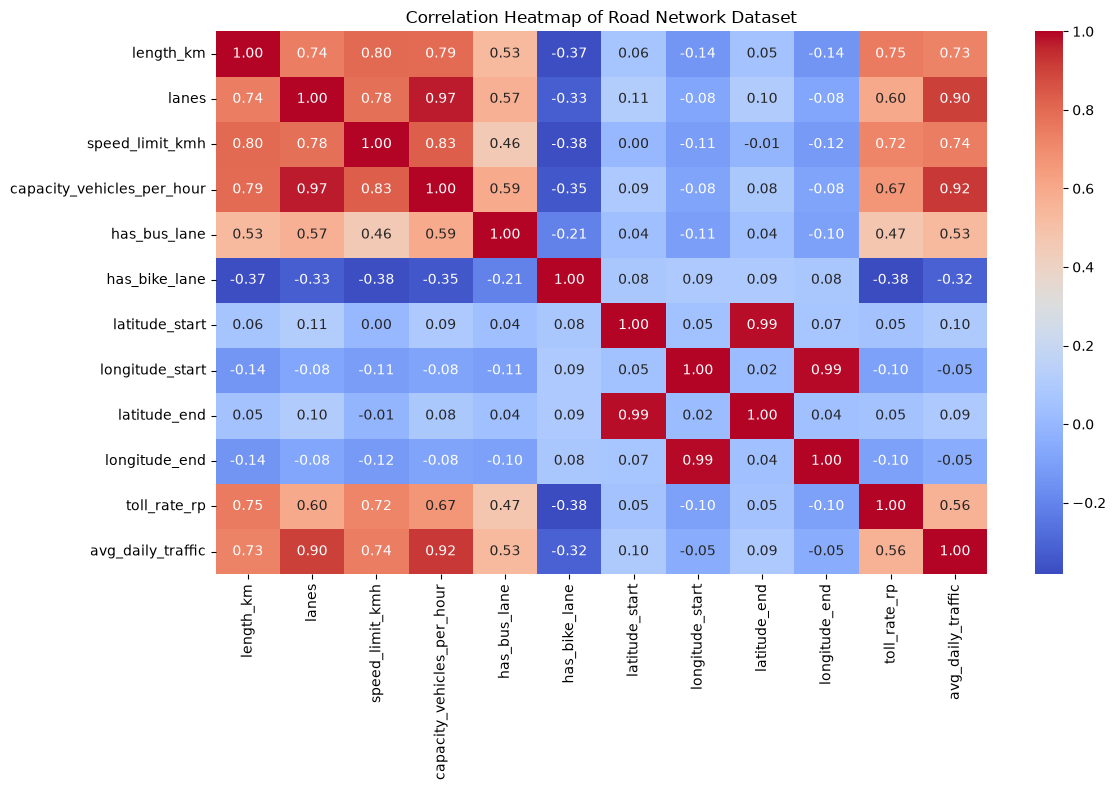

In [40]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Road Network Dataset")
plt.tight_layout()
plt.show()

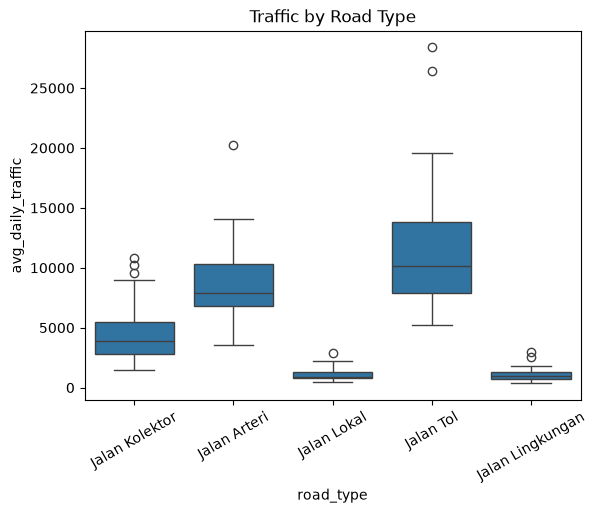

In [41]:
if "road_type" in df.columns:
    sns.boxplot(
        data=df,
        x="road_type",
        y="avg_daily_traffic"
    )

    plt.xticks(rotation=30)
    plt.title("Traffic by Road Type")
    plt.show()

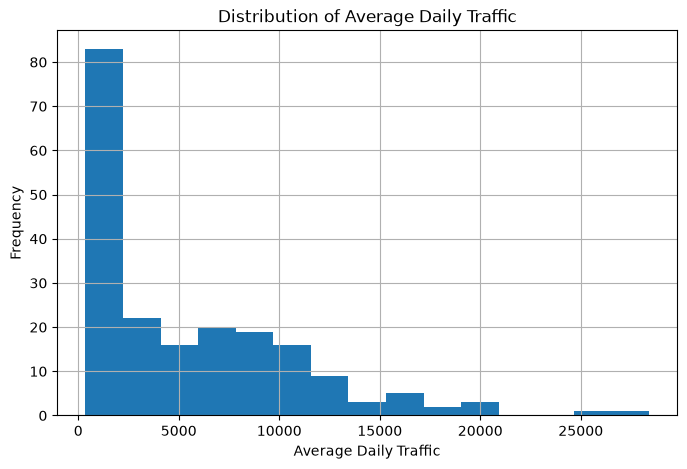

In [42]:
df["avg_daily_traffic"].hist(bins=15, figsize=(8, 5))

plt.title("Distribution of Average Daily Traffic")
plt.xlabel("Average Daily Traffic")
plt.ylabel("Frequency")

plt.show()

In [43]:
df["last_maintenance_date"] = pd.to_datetime(
    df["last_maintenance_date"]
)

df["maintenance_age_days"] = (
    df["last_maintenance_date"].max()
    - df["last_maintenance_date"]
).dt.days

X = df.drop(
    columns=[
        "road_id",
        "road_name",
        "last_maintenance_date",
        "avg_daily_traffic"
    ]
)

y = df["avg_daily_traffic"]

X.head()

C:\Users\HP\AppData\Local\Temp\ipykernel_6728\847860250.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["last_maintenance_date"] = pd.to_datetime(


,road_type,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,surface_condition,latitude_start,longitude_start,latitude_end,longitude_end,district,toll_rate_rp,maintenance_age_days
0,Jalan Kolektor,4.3,4,60,5384,0,0,Cukup,-6.173938,106.920654,-6.187271,106.937674,PIK,0,452
1,Jalan Arteri,4.3,4,80,6132,0,0,Baik,-6.248396,106.768647,-6.246220,106.771962,Depok,0,486
2,Jalan Lokal,1.8,2,40,978,0,0,Cukup,-6.267631,106.814963,-6.264098,106.831007,Tangerang,0,337
3,Jalan Kolektor,1.8,4,60,4160,0,1,Rusak Berat,-6.112216,106.954036,-6.122268,106.958261,Mangga Dua,0,670
4,Jalan Tol,22.7,4,80,6600,1,0,Baik,-6.349760,106.861835,-6.341074,106.856648,Sudirman,7000,30


In [44]:
X = pd.get_dummies(
    X,
    drop_first=True,
    dtype=int
)

X.head()

,length_km,lanes,speed_limit_kmh,capacity_vehicles_per_hour,has_bus_lane,has_bike_lane,latitude_start,longitude_start,latitude_end,longitude_end,...,district_Mangga Dua,district_Menteng,district_PIK,district_Pluit,district_Senayan,district_Senen,district_Slipi,district_Sudirman,district_Sunter,district_Tangerang
0,4.3,4,60,5384,0,0,-6.173938,106.920654,-6.187271,106.937674,...,0,0,1,0,0,0,0,0,0,0
1,4.3,4,80,6132,0,0,-6.248396,106.768647,-6.246220,106.771962,...,0,0,0,0,0,0,0,0,0,0
2,1.8,2,40,978,0,0,-6.267631,106.814963,-6.264098,106.831007,...,0,0,0,0,0,0,0,0,0,1
3,1.8,4,60,4160,0,1,-6.112216,106.954036,-6.122268,106.958261,...,1,0,0,0,0,0,0,0,0,0
4,22.7,4,80,6600,1,0,-6.349760,106.861835,-6.341074,106.856648,...,0,0,0,0,0,0,0,1,0,0


In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((160, 38), (40, 38), (160,), (40,))

In [47]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

X_train_scaled[:5]

array([[-0.74964246, -0.65187276, -0.29032788, -0.49526324, -0.50974751,
         1.24083945,  0.10298793,  0.68571718,  0.12515087,  0.84993584,
        -0.50467831, -0.89051496,  1.88982237, -0.53881591, -0.4404882 ,
        -0.59660054, -0.70379479, -0.24413654, -0.29738086, -0.24413654,
        -0.16012815, -0.22941573, -0.19738551, -0.27170849, -0.1796053 ,
        -0.21389632, -0.16012815, -0.21389632,  3.        , -0.29738086,
        -0.30966177, -0.1796053 , -0.22941573, -0.22941573, -0.1796053 ,
        -0.24413654, -0.19738551, -0.1796053 ],
       [-0.86565733, -0.65187276, -1.30753503, -0.77789355, -0.50974751,
        -0.80590603, -1.71352525, -1.39497409, -1.77634062, -1.54691399,
        -0.50467831, -0.80309116, -0.52915026,  1.85592145, -0.4404882 ,
        -0.59660054,  1.42086872, -0.24413654, -0.29738086,  4.09606858,
        -0.16012815, -0.22941573, -0.19738551, -0.27170849, -0.1796053 ,
        -0.21389632, -0.16012815, -0.21389632, -0.33333333, -0.29738086,
   

In [48]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(),
    "Lasso Regression": Lasso(max_iter=10000),
    "ElasticNet Regression": ElasticNet(max_iter=10000)
}

pd.DataFrame({
    "Model": list(models.keys())
})

,Model
0,Linear Regression
1,Ridge Regression
2,Lasso Regression
3,ElasticNet Regression


In [49]:
for model in models.values():
    model.fit(X_train_scaled, y_train)

In [50]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,MSE,RMSE,R2
0,Linear Regression,1322.025264,3.107776e+06,1762.888433,0.830028
1,Ridge Regression,1221.423060,2.794952e+06,1671.811030,0.847137
2,Lasso Regression,1303.364151,3.057123e+06,1748.463087,0.832798
3,ElasticNet Regression,1357.322455,3.148539e+06,1774.412351,0.827799


In [52]:
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

results_df

,Model,MAE,MSE,RMSE,R2
0,Ridge Regression,1221.423060,2.794952e+06,1671.811030,0.847137
1,Lasso Regression,1303.364151,3.057123e+06,1748.463087,0.832798
2,Linear Regression,1322.025264,3.107776e+06,1762.888433,0.830028
3,ElasticNet Regression,1357.322455,3.148539e+06,1774.412351,0.827799


In [53]:
best_model_name = results_df.loc[0, "Model"]

best_model = models[best_model_name]

best_model_name

'Ridge Regression'

In [54]:
import pickle

with open("model.pkl", "wb") as f:
    pickle.dump(best_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

with open("features.pkl", "wb") as f:
    pickle.dump(X.columns.tolist(), f)